# Reddit pilot: audited data to Independent Leiden

This notebook replays **real recorded results**, verifies their provenance, and produces fourteen descriptive figure families. Tracking, features and forecasting evaluation are not implemented. Subreddit names describe activity contexts, not ground-truth user communities.

## Setup and kernel (run once in a terminal at the repository root)
Python **3.11+** is required. In Windows PowerShell:
```powershell
python -m venv .venv
& .\.venv\Scripts\python.exe -m pip install -e '.[graph,notebook]'
& .\.venv\Scripts\python.exe -m ipykernel install --prefix .venv --name reddit-sna --display-name 'Reddit SNA (.venv)'
```
In VS Code, install the Python and Jupyter extensions, click **Select Kernel > Python Environments** and choose this repository's `.venv\Scripts\python.exe`. Restart the kernel after installing dependencies. In Jupyter, select `Reddit SNA (.venv)` if available; otherwise select the same interpreter. Linux/macOS use `.venv/bin/python`.

Run **Restart Kernel > Run All**. The first cell prints the interpreter and gives actionable setup errors. No cell installs packages or edits `sys.path`. The `00_research_plan.ipynb` files are unfinished templates; this is the executable pilot.
## Frozen week-one validation protocol

The main pilot now covers **2015-01 through 2015-12 UTC**, exclusively within official train. Gamma 1 and seeds 0/1/2 remain fixed. The original three-month cohort stays immutable. A separate sensitivity run uses January-March at gamma 0.5/1/2 and 5% unique-edge deletion with predefined seeds; it never replaces canonical memberships. Three predeclared context graphs attribute replies to the child corpus: AskALiberal, moderatepolitics and PoliticalDiscussion.

For a new checkout with local raw inputs, produce the required artifacts using these commands (use new IDs if they already exist):
```powershell
& .\.venv\Scripts\python.exe -m reddit_sna prepare --config configs/core.toml --start 2015-01 --end 2016-01 --run-id reddit-pilot-2015-v1
& .\.venv\Scripts\python.exe -m reddit_sna.reporting.validation --project . --detection-run reddit-pilot-2015-v1 --output-id reddit-2015-validation-v1
& .\.venv\Scripts\python.exe -m reddit_sna.reporting.validation --project . --detection-run reddit-pilot-2015-v1 --output-id reddit-quarter-validation-v1 --sensitivity
```
The final command evaluates only January-March of the specified cohort for sensitivity, while validating its full input chain. On this workstation the preserved ordered quarter sensitivity run uses `reddit-quarter-ordered-detection-v1`, so its reference differs from the annual cohort. That distinction is verified and printed below; do not join their user IDs or partitions. Rebuilding all raw data can take many minutes; replay checks existing results without a raw rescan.

### Causal ordering protocol

A real aligned check of the historical v2 quarter and annual runs found identical January-March graphs but different partitions in all three months. Seed repeatability within a run did not protect against ordinal user renumbering across normalization cutoffs. New snapshots use **reply-r-v3-order1**: per-user keys hash the minimum retained authored-record ID **through the snapshot month**, and both detector vertices and edge insertion order follow canonical indices. Raw author names are never used as ordering keys. The sidecar is `node_order.csv` and is bound into graph/reference hashes.

The development replay selects `reddit-2015-ordered-detection-v1`, rebuilt from verified annual metadata without rescanning raw. Quarterly sensitivity selects `reddit-quarter-ordered-validation-v1`. On a fresh checkout, the `prepare` command above produces the new protocol directly; set `DETECTION_RUN` and both validation run selectors to the IDs you actually created. Never reuse a completed output ID. The previous v2 artifacts remain immutable evidence of the detected problem, not canonical handoff results.


In [1]:
# Check the active kernel before importing the project, so setup errors are clear.
import importlib.util
import sys
print("Active Python:", sys.executable)
if sys.version_info < (3, 11):
    raise RuntimeError("Select a Python 3.11+ project .venv kernel.")
missing = [name for name in ("reddit_sna", "matplotlib", "numpy", "igraph", "leidenalg")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(
        f"Missing {missing} in {sys.executable}. Select the project .venv kernel. "
        'In a terminal, use that Python to run: python -m pip install -e ".[graph,notebook]". '
        "Then restart the kernel and Run All."
    )
import os
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display
from reddit_sna.config import load_config
from reddit_sna.pipelines.preparation import run_preparation
from reddit_sna.reporting.pilot import load_pilot
from reddit_sna.reporting.figures import build_figures, export_figures
import matplotlib.pyplot as plt


Active Python: <PROJECT_ROOT>\.venv\Scripts\python.exe


## Input selection and replay versus rebuild

Paths are resolved from the working directory or `REDDIT_SNA_PROJECT`; they never depend on a personal absolute path. The default detection run below is the documented pilot, not an automatic choice of the best result. Its graph and normalization sources are followed from recorded manifests. To select another run, edit `DETECTION_RUN` or set `REDDIT_DETECTION_RUN`; setting it to `None` requires exactly one candidate.

**REPLAY** checks the existing data-to-membership chain, including every recorded artifact hash. It does not scan raw data again. **REBUILD** scans all 15 original ZIPs and runs audit, normalization, snapshots and detection using the same API as the CLI. It takes substantially longer and requires local raw data. Every rebuild/export uses a fresh output ID; existing runs remain immutable.


In [2]:
# Search upward because editors may start the kernel in the notebook folder.
search = Path(os.environ.get("REDDIT_SNA_PROJECT", Path.cwd())).resolve()
ROOT = next((p for p in (search, *search.parents)
             if (p / "pyproject.toml").is_file() and (p / "src/reddit_sna").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Set REDDIT_SNA_PROJECT to the repository directory and rerun.")
REBUILD = False
DETECTION_RUN = os.environ.get("REDDIT_DETECTION_RUN", "reddit-2015-ordered-detection-v1")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
if REBUILD:
    # All stages share one new run; no raw archives are extracted or changed.
    rebuilt = run_preparation(load_config(ROOT / "configs/core.toml", run_id=f"reddit-pilot-{STAMP}"), start="2015-01", end="2016-01")
    DETECTION_RUN = rebuilt.name
pilot = load_pilot(ROOT, DETECTION_RUN)
print("Mode:", "REBUILD RAW" if REBUILD else "REPLAY VERIFIED ARTIFACTS")
print("Verified runs:", {stage: path.name for stage, path in pilot["runs"].items()})
print("Observed interval:", pilot["graphs"]["start_month"], "to", pilot["graphs"]["end_month_exclusive"], "(exclusive, UTC)")
print("Graph reference:", pilot["graphs"]["graph_reference"])
print("Producer versions:", pilot["detection"]["versions"])


Mode: REPLAY VERIFIED ARTIFACTS
Verified runs: {'detection': 'reddit-2015-ordered-detection-v1', 'graphs': 'reddit-2015-ordered-graphs-v1', 'normalized': 'reddit-pilot-2015-v1'}
Observed interval: 2015-01 to 2016-01 (exclusive, UTC)
Graph reference: reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de
Producer versions: {'igraph': '1.0.0', 'leidenalg': '0.12.0'}


## Graph semantics and descriptive evaluation

A directed reply links the comment author to the parent author at the child's timestamp. Parents may precede the pilot but cannot follow the child. Self-replies and excluded authors do not form edges. The undirected projection sums both directions: `R_uv = replies_uv + replies_vu`. Only endpoint users receive memberships; observed isolates are retained in coverage counts.

Independent Leiden optimizes weighted RBConfiguration at the recorded gamma separately for each month and seed. The first configured seed is canonical; it is not selected by its score. Community IDs are local to a month, and users are comparable only inside the recorded identity scope. Modularity measures graph quality; pairwise seed ARI measures repeatability. Neither establishes social validity or forecasting accuracy.
New protocol node order is derived from past-only record anchors; canonical edge-index insertion order prevents ordinal-ID changes from silently changing seeded inputs. Legacy v2 cohorts retain their original ordering semantics and must be kept separate.


In [3]:
# Show aggregate diagnostics; never display author names, discussion text or user IDs.
graphs, detection = pilot["graphs"], pilot["detection"]
for graph, result in zip(graphs["months"], detection["months"]):
    canonical = next(r for r in result["runs"] if r["seed"] == detection["canonical_seed"])
    print({"month": graph["month"], "reply_events": graph["reply_events"],
           "active_authors": graph["active_authors"], "reply_endpoints": graph["reply_endpoints"],
           "active_coverage": graph["reply_coverage_active_authors"],
           "communities": canonical["communities"], "modularity": canonical["modularity"],
           "seed_pair_ARI": result["seed_pair_ARI"]})


{'month': '2015-01', 'reply_events': 50458, 'active_authors': 8686, 'reply_endpoints': 8222, 'active_coverage': 0.9401335482385448, 'communities': 129, 'modularity': 0.6416905180808229, 'seed_pair_ARI': [0.9573838699185876, 0.9626387488863225, 0.9616455995365751]}
{'month': '2015-02', 'reply_events': 49841, 'active_authors': 8575, 'reply_endpoints': 8229, 'active_coverage': 0.9520699708454811, 'communities': 105, 'modularity': 0.6731224507029991, 'seed_pair_ARI': [0.9711729748031303, 0.9793781446567992, 0.9708618026302459]}
{'month': '2015-03', 'reply_events': 60407, 'active_authors': 9839, 'reply_endpoints': 9357, 'active_coverage': 0.9416607378798658, 'communities': 115, 'modularity': 0.6546293004930365, 'seed_pair_ARI': [0.9835777200090225, 0.9762697868750296, 0.9838594688129279]}
{'month': '2015-04', 'reply_events': 71996, 'active_authors': 12495, 'reply_endpoints': 11947, 'active_coverage': 0.9498999599839936, 'communities': 98, 'modularity': 0.6676031440450079, 'seed_pair_ARI': [

## Figures 1–2: data scope and corpus support

Raw scanned rows, retained pre-cutoff metadata, historical parents and pilot activity are overlapping populations. Figure 1 uses a labeled symlog axis to keep them readable; historical metadata is not a preprocessing loss. Figure 2 retains every declared corpus-month, with counts annotated and color `log(1 + records)`; **zero observed activity does not prove a corpus did not exist**.


## Verified analysis and sensitivity sources

Analysis and the automated handoff consumer are independent checks of public files; acceptance by a person is still unverified. Verify every validation artifact hash and the source manifests before reading results. The annual analysis must match the main notebook cohort. Sensitivity can use a separate quarter cohort; its source is explicitly reported and no cross-cohort ID matching is attempted.


In [4]:
from reddit_sna.reporting.pilot import verified_manifest, read_json
from reddit_sna.reporting.validation import validate_pilot
from reddit_sna.reporting.validation_figures import build_validation_figures
from reddit_sna.data.archive import digest_file

if REBUILD:
    # Build matching analysis for this newly reserved annual run, without replacing old results.
    annual_run = validate_pilot(ROOT, DETECTION_RUN, f"reddit-analysis-{STAMP}")
else:
    annual_run = ROOT / "artifacts/core" / os.environ.get("REDDIT_ANALYSIS_RUN", "reddit-2015-ordered-validation-v1")
quarter_run = ROOT / "artifacts/core" / os.environ.get("REDDIT_SENSITIVITY_RUN", "reddit-quarter-ordered-validation-v1")
validation_manifests = {}
for label, run in (("annual", annual_run), ("sensitivity", quarter_run)):
    manifest = verified_manifest(run, ROOT / "artifacts")
    for stage, source in manifest["source_runs"].items():
        source = Path(source)
        verified_manifest(source, ROOT / "artifacts")
        if digest_file(source / "manifest.json") != manifest["source_manifest_sha256"][stage]:
            raise ValueError("Validation source manifest changed")
    validation_manifests[label] = manifest
if validation_manifests["annual"]["graph_reference"] != graphs["graph_reference"]:
    raise ValueError("Annual analysis must match the notebook's main graph cohort")
analysis = read_json(annual_run / "network_analysis.json")
sensitivity_results = read_json(quarter_run / "sensitivity.json")
if [r["month"] for r in analysis["months"]] != graphs["actual_months"]:
    raise ValueError("Annual analysis period mismatch")
print("Annual validation:", annual_run.name)
print("Sensitivity validation:", quarter_run.name)
print("Sensitivity source graph reference:", validation_manifests["sensitivity"]["graph_reference"])
print("Automated handoff:", read_json(annual_run / "handoff.json")["status"])
print("Partner acceptance: not verified; forecasting and class support remain pending")


Annual validation: reddit-2015-ordered-validation-v1
Sensitivity validation: reddit-quarter-ordered-validation-v1
Sensitivity source graph reference: reply-r-v3-order1:1c9d128e23f24f5596cba3eed883feda90babd9dff9280906b8ce50d895e6589
Automated handoff: accepted_by_automated_consumer
Partner acceptance: not verified; forecasting and class support remain pending


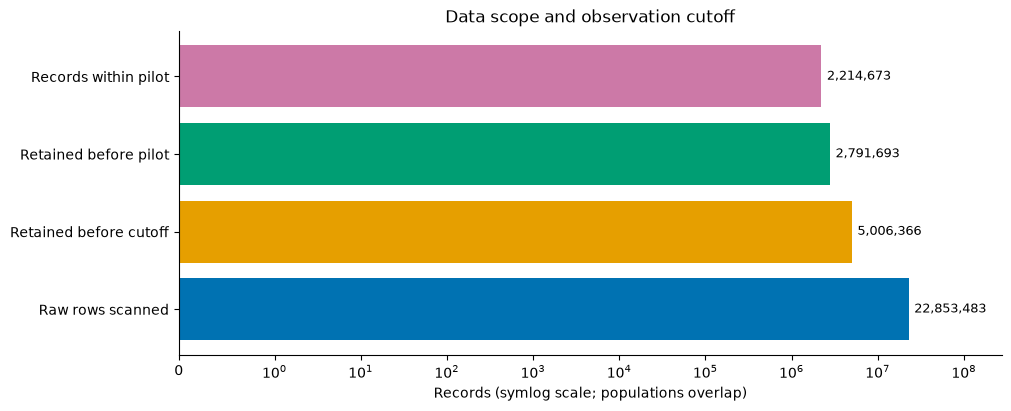

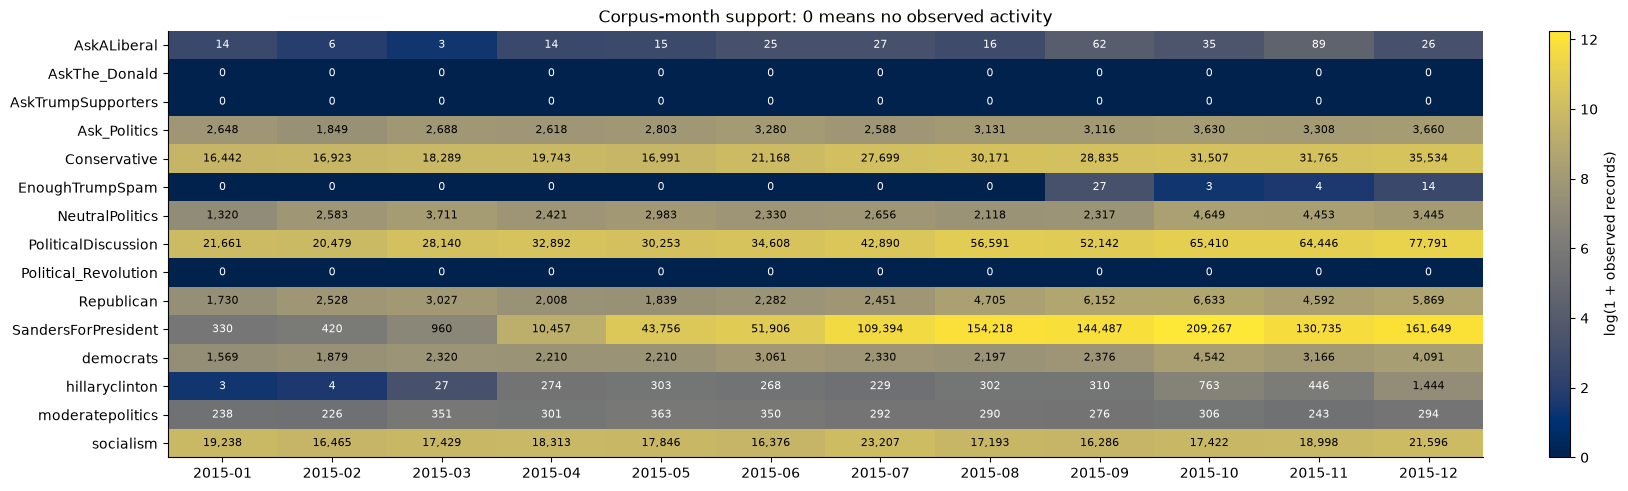

In [5]:
# Build all figures from verified summaries; full-graph metrics are never estimated from the display sample.
SAMPLE_LIMIT, DISPLAY_SEED = 150, 42
plt.ioff()  # Display each figure explicitly once; avoid duplicate inline output.
with plt.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    figures = build_figures(pilot, sample_limit=SAMPLE_LIMIT, seed=DISPLAY_SEED)
    figures.update(build_validation_figures(analysis, sensitivity_results))
# Detach figures from pyplot auto-display; the retained objects still display/export.
for fig in figures.values():
    plt.close(fig)
for name in ("01_data_scope", "02_corpus_support"):
    display(figures[name])


## Figures 3–5: graph volume, coverage and exclusive reply outcomes

Active authors and reply endpoints are distinct: endpoints can include historical parent-only users. Observed users are their union. Active coverage is covered active authors / active authors; observed coverage is endpoints / observed users. Undefined ratios remain missing, not zero.

Reply outcomes use the fixed priority: no pointer, missing parent, excluded child author, excluded parent author, future parent, self-reply, valid. They sum to comments. Older incidence counters can overlap and must not be stacked as losses. Unique authors across corpora are also not additive.


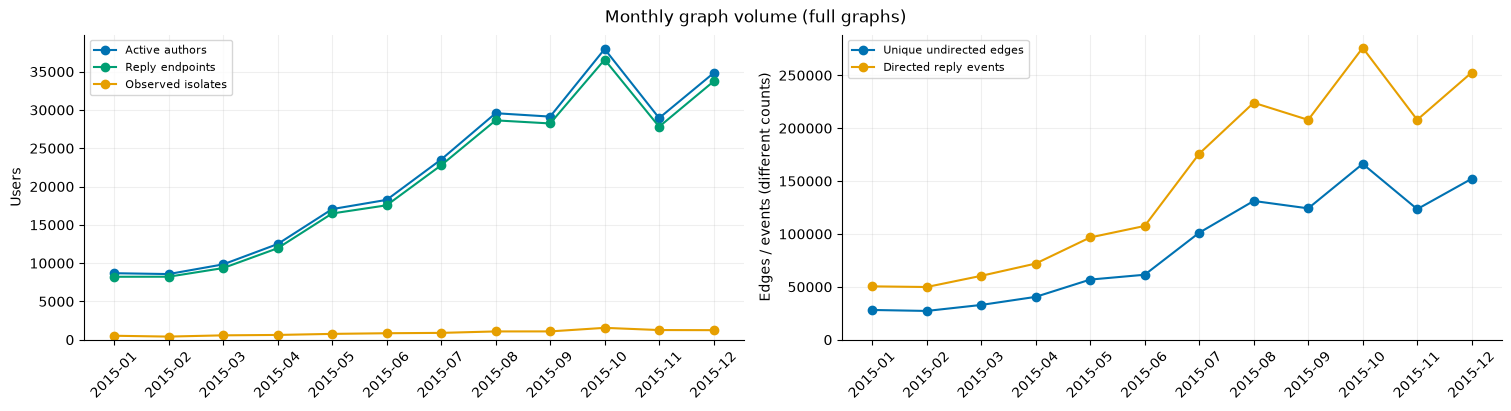

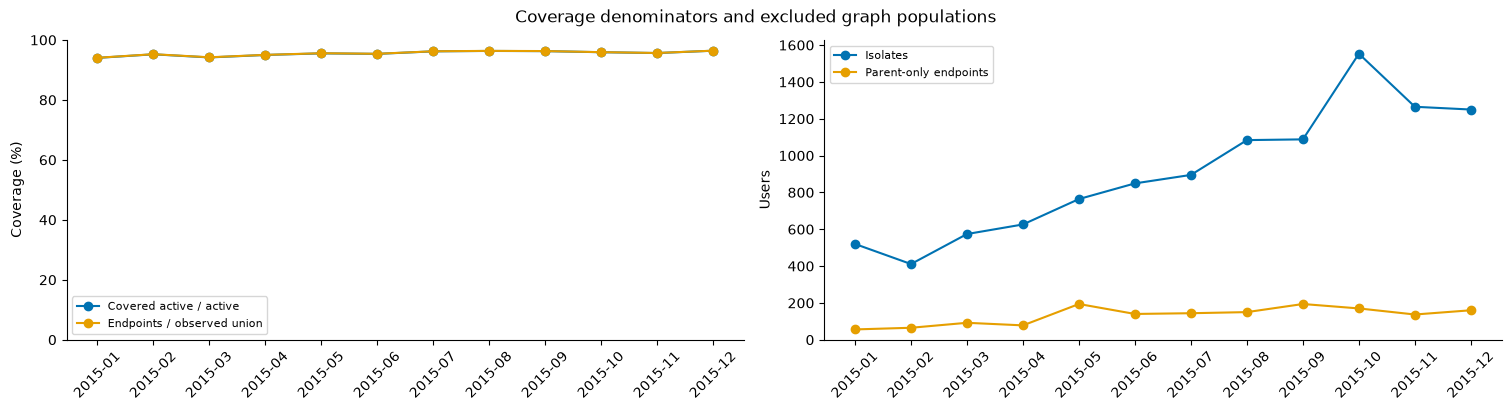

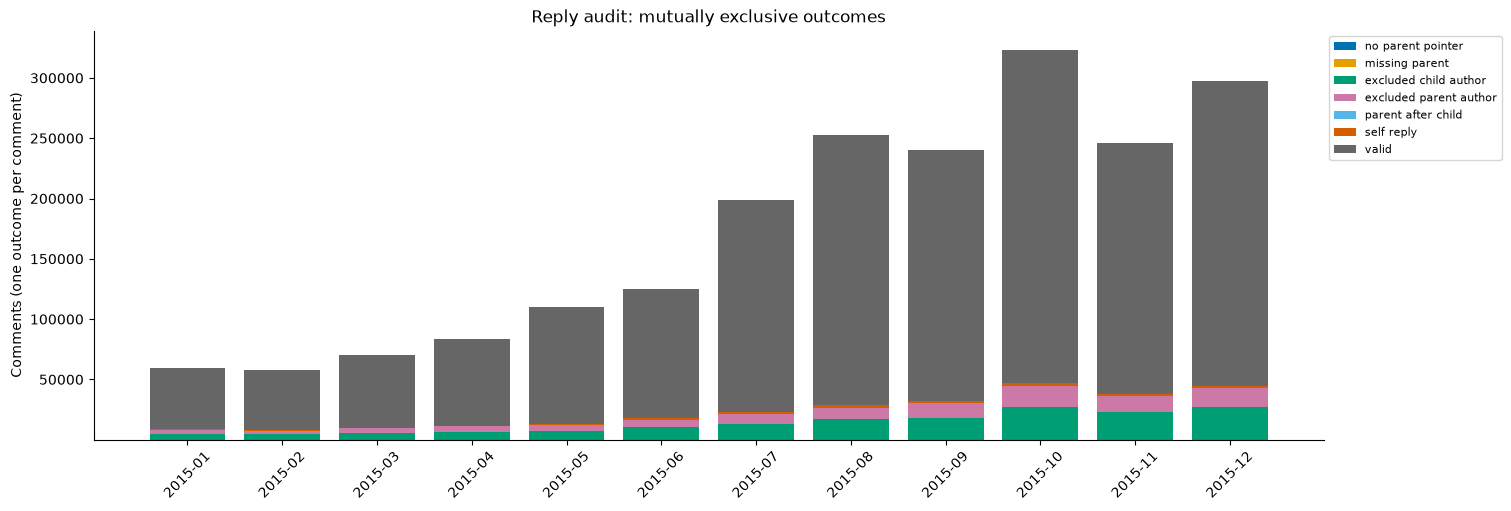

In [6]:
for name in ("03_graph_volume", "04_coverage", "05_reply_outcomes"):
    display(figures[name])


## Figures 6–8: community sizes, repeatability and a network illustration

The empirical size distribution uses the full canonical partition and a logarithmic size axis; empty partitions are omitted. Quality and ARI panels show recorded diagnostics without confidence intervals: seed pairs are dependent repeats, not independent test sets.

The network figure shows up to 150 nodes reached by seeded BFS in the first month's largest component, with induced edges and full-graph community colors. It is a **biased illustration**, not a representative sample. Colors can repeat and have no temporal alignment. No user labels are exposed; the unweighted layout does not affect detection.


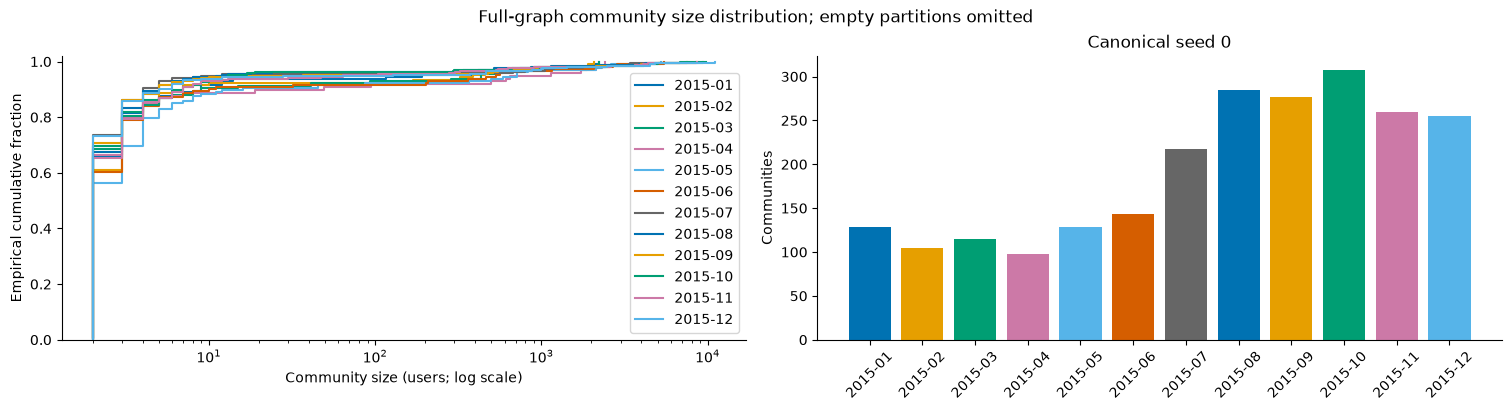

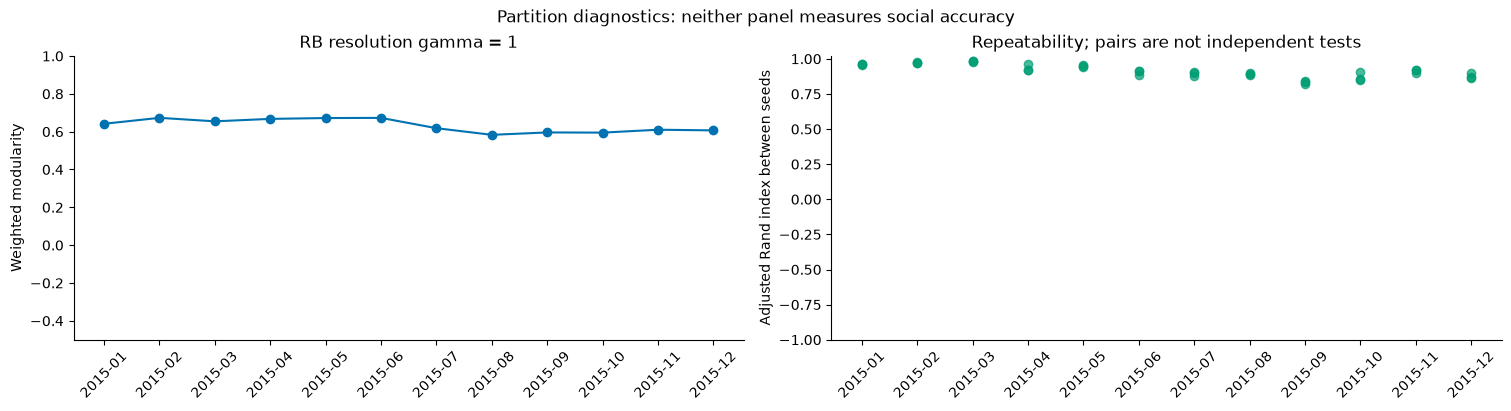

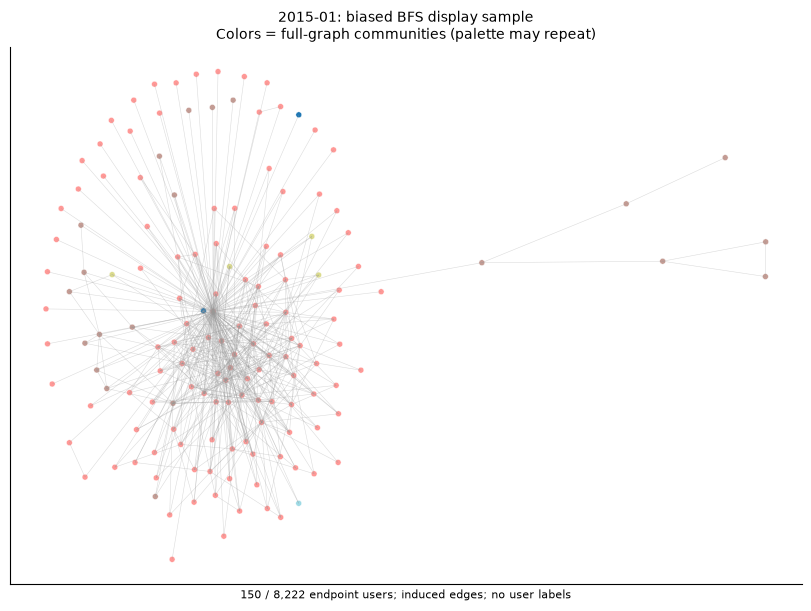

In [7]:
for name in ("06_community_sizes", "07_partition_diagnostics", "08_network_sample"):
    display(figures[name])


## Figures 9-12: structure, concentration and predeclared contexts

Largest-component support and density use the observed user union, including isolates. Degree counts distinct neighbors; strength sums incident reply weights and its network total is **twice** the reply-event count. CCDFs show quarter-start months, selected in advance for readability, with x=0 omitted only from the logarithmic axis, not from the denominator. A heavy tail alone does not establish a power law.

Top-user strength concentration uses `ceil(1% * observed users) / total strength`. Corpus HHI is the sum of squared attributed-event shares. These describe concentration without proving causality. Context graphs count replies by the child's corpus with parent endpoints allowed elsewhere; user sets overlap, so they cannot be added or treated as true communities. Density and context support must be considered when comparing months.


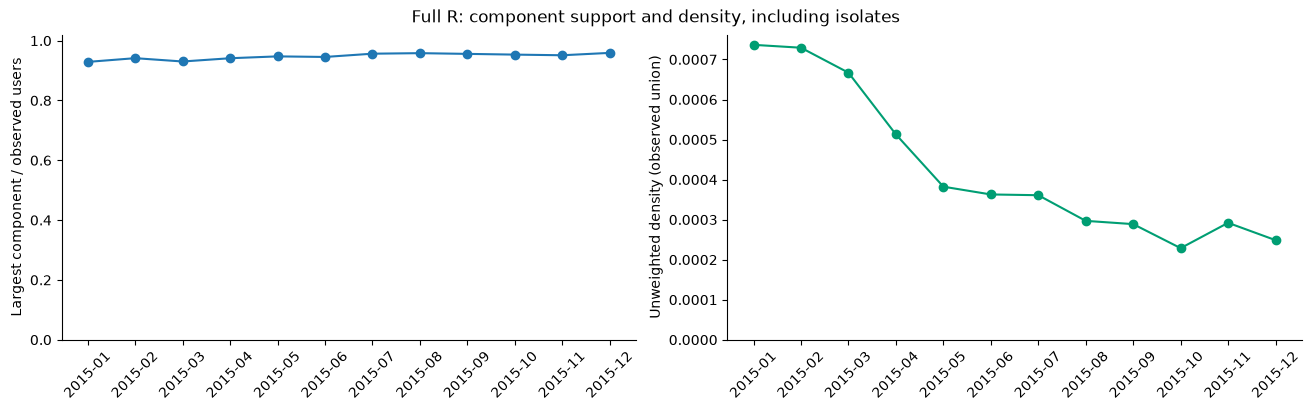

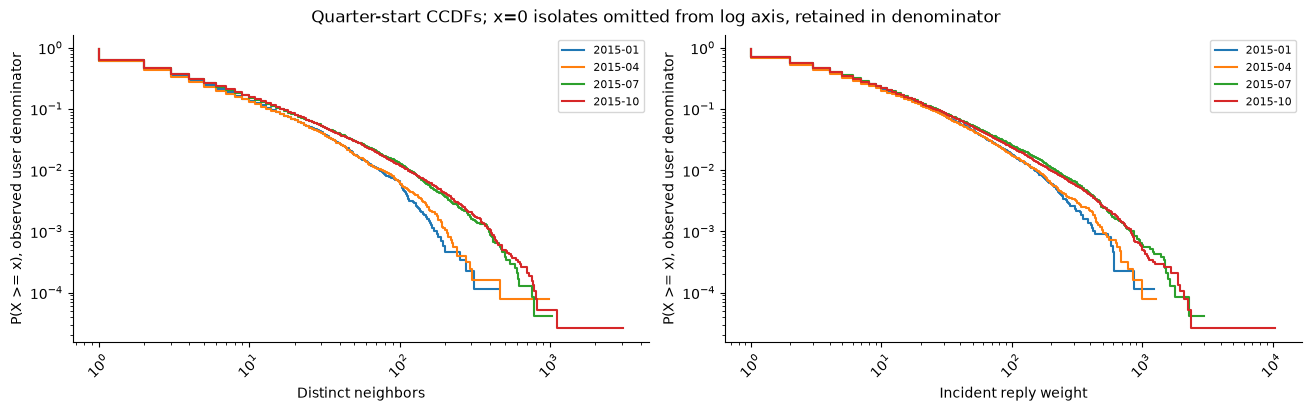

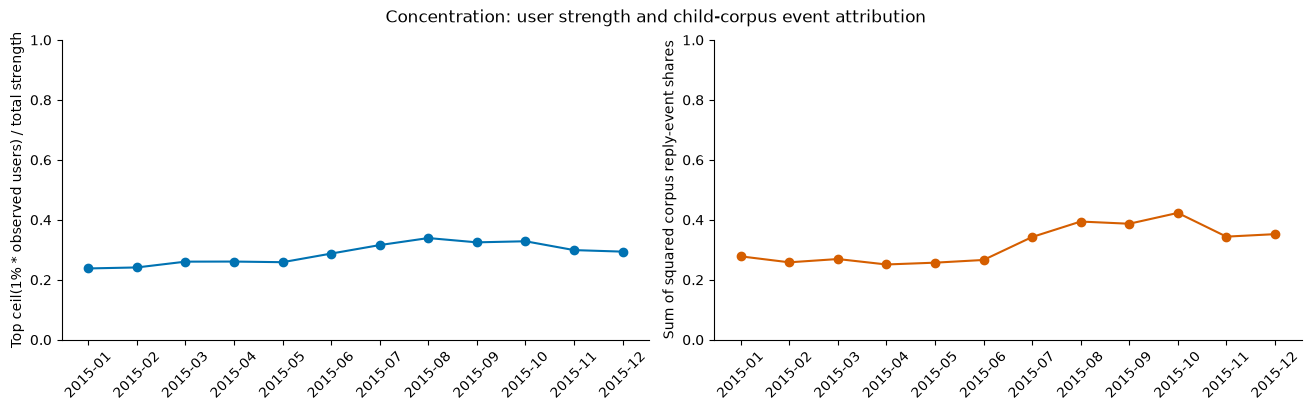

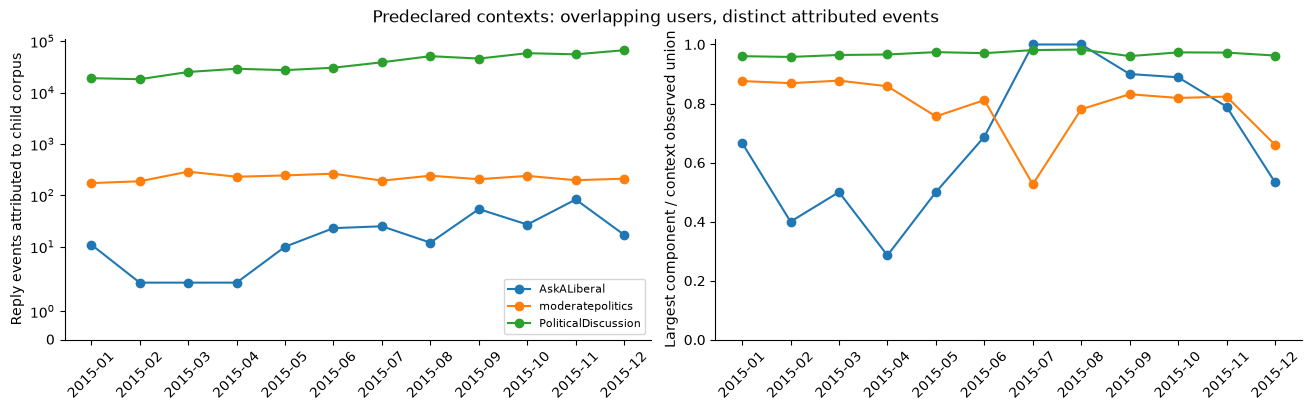

{'month': '2015-01', 'observed_users': 8742, 'components': 569, 'largest_component_fraction_observed': 0.9289636238846946, 'top_one_percent_strength_share': 0.2378215545602283, 'corpus_share_hhi': 0.27817247993869043}
{'month': '2015-02', 'observed_users': 8640, 'components': 454, 'largest_component_fraction_observed': 0.9414351851851852, 'top_one_percent_strength_share': 0.24114684697337532, 'corpus_share_hhi': 0.25825391332185393}
{'month': '2015-03', 'observed_users': 9931, 'components': 630, 'largest_component_fraction_observed': 0.9303192024972309, 'top_one_percent_strength_share': 0.26048305659940074, 'corpus_share_hhi': 0.2691782977286369}
{'month': '2015-04', 'observed_users': 12573, 'components': 678, 'largest_component_fraction_observed': 0.9412232561838861, 'top_one_percent_strength_share': 0.26077837657647646, 'corpus_share_hhi': 0.25105189117910665}
{'month': '2015-05', 'observed_users': 17249, 'components': 830, 'largest_component_fraction_observed': 0.947417241579222, 't

In [8]:
for name in ("09_components_density", "10_degree_strength", "11_interaction_concentration", "12_context_diagnostics"):
    display(figures[name])
# Aggregate numerical summaries make small plot differences auditable.
for row in analysis["months"]:
    print({key: row[key] for key in ("month", "observed_users", "components", "largest_component_fraction_observed",
                                   "top_one_percent_strength_share", "corpus_share_hhi")})


## Figures 13-14: fixed gamma and edge-perturbation diagnostics

Each point is a month/seed diagnostic, not an independent evaluation sample. Gamma comparisons keep graph weights fixed. Edge perturbation removes `floor(0.05 * unique undirected edges)` uniformly without replacement, retains the remaining weights and reruns gamma 1. Common-user ARI is accompanied by the fraction of baseline endpoint users retained. Fewer than two common users or a constant partition yields no informative ARI here; missing values are not perfect stability.

Modularity across different gamma objectives is not a selection rule. The baseline remains gamma 1 / canonical seed 0. Same-seed gamma-1 replay is separately checked for partition equality under cluster renaming. A mismatch is reported rather than hidden by picking another seed. Repeatability and sensitivity do not validate social truth or tracker labels.


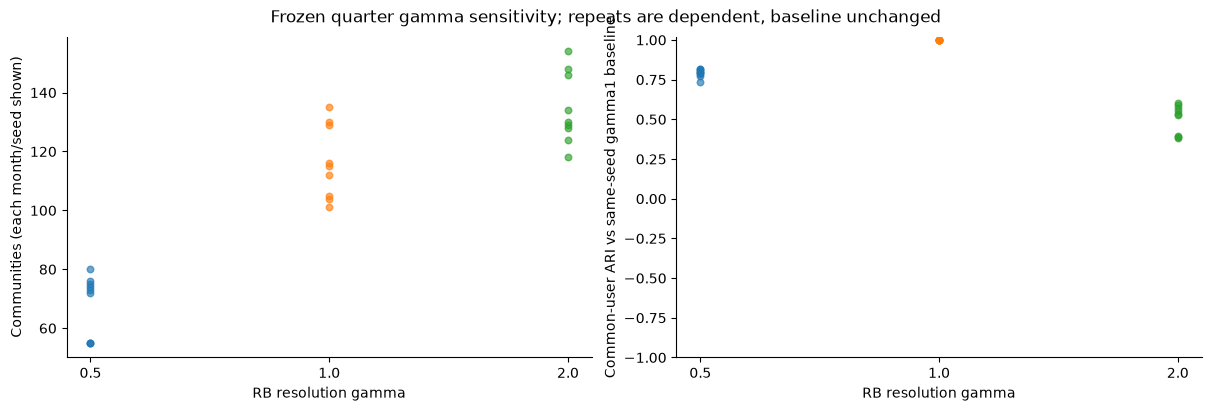

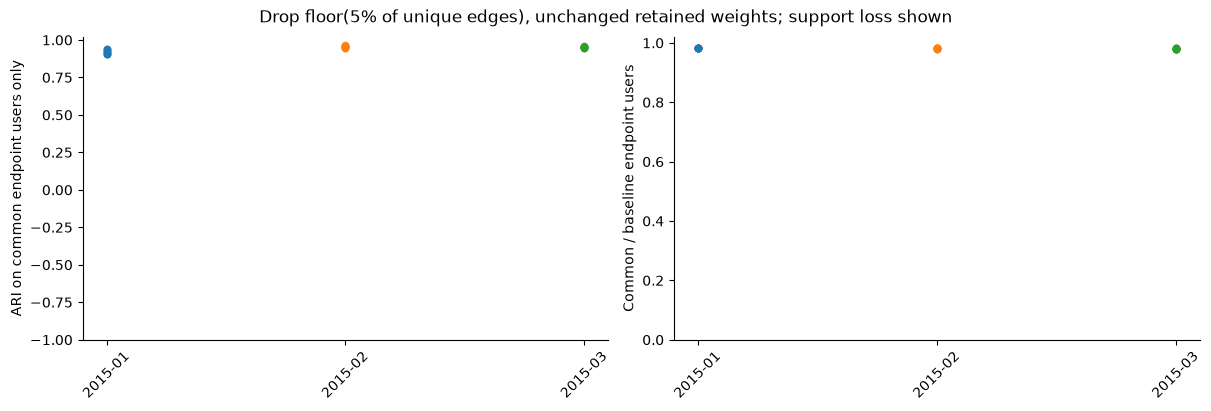

Same-seed gamma1 replay checks: [True, True, True, True, True, True, True, True, True]
Frozen schedule: {'months': ['2015-01', '2015-02', '2015-03'], 'gammas': [0.5, 1.0, 2.0], 'detector_seeds': [0, 1, 2], 'edge_drop_fraction': 0.05, 'drop_seeds': [100, 101, 102]}


In [9]:
for name in ("13_gamma_sensitivity", "14_edge_perturbation"):
    display(figures[name])
replay_checks = [r["baseline_replay_partition_equal"] for r in sensitivity_results["runs"]
                 if r["baseline_replay_partition_equal"] is not None]
print("Same-seed gamma1 replay checks:", replay_checks)
print("Frozen schedule:", sensitivity_results["schedule"])


## Export and publication

Export all fourteen figures as PNG (180 dpi) and SVG under a new local artifact directory, alongside source and validation-manifest hashes, plotting versions, graph reference and sampling policy. The tracked notebook includes a reviewed execution snapshot so GitHub can display code, tables and figures. GitHub previews are static; download the repository and use the project kernel to rerun cells. Standalone runtime artifacts and private files remain local. Machine-specific project paths in saved text outputs are replaced with `<PROJECT_ROOT>`; numerical results and figure images are unchanged.

In [10]:
# Fresh directories prevent a later Run All from silently replacing published figures.
FIGURE_OUTPUT = ROOT / "artifacts/core" / f"reddit-pilot-figures-{STAMP}"
export_figures(figures, FIGURE_OUTPUT, pilot, sample_limit=SAMPLE_LIMIT, seed=DISPLAY_SEED,
               validation_runs=(annual_run, quarter_run))
print("Figures and provenance:", FIGURE_OUTPUT)
for fig in figures.values():
    plt.close(fig)


Figures and provenance: <PROJECT_ROOT>\artifacts\core\reddit-pilot-figures-20261016T025426534284Z


## Limitations and next experiments

Twelve observed months provide **eleven potential transitions**, not guaranteed sample/class support or a valid forecasting evaluation. The preparation pipeline still stops at memberships; the partner's tracker/features/model and complete pair evaluation remain unfinished. Zero-support corpora, missing historical parents, uneven participation and incomplete bot exclusion constrain interpretation. Pseudonyms do not guarantee anonymity.

The handoff consumer verifies interface readiness, not actual partner acceptance or collaborator invitations. A clean local installation checks reproducibility on this machine, not independent replication by another person. Exact metric/contract tests and tiny planted adapter checks are software evidence, not a formal community-detection benchmark or proof of novelty.

Next research stages are independent difficult planted benchmarks, validated tracking, cutoff-safe features, fair out-of-time prediction baselines and closest-work comparison. Keep alternate reference cohorts separate and report null results. No official test data are used for pilot selection. See `reports/REDDIT-PILOT.md` for observed findings, alternative explanations and remaining obligations. Maximum marks or paper potential cannot be established from figures and tests alone.
